<a href="https://colab.research.google.com/github/sammanfatima/Deep-Learning-with-TensorFlow/blob/main/02_multilayer_perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Multilayer Perceptron**

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

In [2]:
# remove warnings
import warnings
warnings.filterwarnings('ignore')

# load titanic dataset
df = sns.load_dataset('tips')

# preprocessing
# converting categorical varibales to dummy variables
df = pd.get_dummies(df, drop_first=True)

# selecting features and target
X = df.drop('tip', axis=1)
y = df['tip']

# splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Standardizing the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# **Building the model**

In [4]:
# build the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

In [13]:
# compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

In [14]:
# training the model
model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=1)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7147 - mae: 0.6078  
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6907 - mae: 0.5925 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6904 - mae: 0.5905 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6968 - mae: 0.5902 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6857 - mae: 0.5898 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6857 - mae: 0.5944 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6739 - mae: 0.5856 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6728 - mae: 0.5856 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6748 - mae: 0.5849 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6744 - mae: 0.5888 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6873 - mae: 0.5986 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6850 - mae: 0.5956 
Epoch 13/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/ste

In [15]:
# evaluating the model (using mean squared error)
loss = model.evaluate(X_test, y_test, verbose=0)
print('Mean Squared Error:', loss)

Mean Squared Error: [1.4531614780426025, 0.8745521903038025]


Mean Squared Error: [1.1615701913833618, 0.8385095596313477]


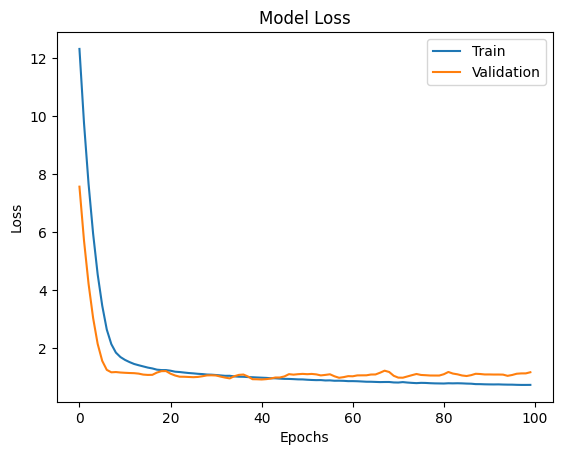

In [17]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

# compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# tain the model and plot the training and testing loss and accuracy
history = model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0, validation_data=(X_test, y_test))

# evaluating the model using MSE
loss = model.evaluate(X_test, y_test, verbose=0)
print('Mean Squared Error:', loss)

# Plotting the training and testing loss
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Testing Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()
